# Figure S14: eQTL discovery across studies

eQTL credible-set discovery across sample sizes in All of Us, INTERVAL, and TOPMed, with GTEx tissue comparisons and a shared protein-coding gene analysis.


## Run the notebook

Use the R kernel. Start in the repository root. Set `QTL_INPUT_ROOT` to the
source result tables and `QTL_SUSIE_ROOT` to the separate fine-mapping tables.
Set `QTL_PAPER_ROOT` to the local reference directory and `QTL_SOURCE_ROOT`
to the figure checkout. Set these variables in R before running the cells.
Paths can contain spaces.

Run the cells from top to bottom. The cells show input reads, filters, joins,
counts, models, and plot construction. Intermediate objects stay in this R
session. New PDFs and PNGs go to
`notebook_outputs/`. The plotting scripts are in `notebooks/current/`.


## Source scripts

The processing steps below follow these preparation scripts. The source data are not included in Git.

- [fig1_gene_reference](../../preparation/Fig1/00_gene_reference.R): Extract the GENCODE v48 gene records and stable IDs from the raw GTF.
- [s14_discovery](../current/supplements/S14.R): Count source AoU, GTEx, INTERVAL and TOPMed credible sets; select the shared coding-gene intersection; count cohort samples; fit descriptive curves and prepare GTEx envelopes.

The notebook runs the processing in its own cells. The preparation guide lists the original input requirements and missing inputs.


## Setup

Validate the local input paths and load the plot libraries.


In [1]:
# Shared setup for the figure notebooks.
suppressPackageStartupMessages({
  library(tidyverse)
  library(patchwork)
})
if (requireNamespace("showtext", quietly = TRUE)) showtext::showtext_auto(FALSE)

paper_root <- Sys.getenv("QTL_PAPER_ROOT")
source_root <- Sys.getenv("QTL_SOURCE_ROOT", getwd())
input_root <- Sys.getenv("QTL_INPUT_ROOT", source_root)
susie_root <- Sys.getenv("QTL_SUSIE_ROOT", input_root)
repo_root <- getwd()
notebook_output <- Sys.getenv("QTL_NOTEBOOK_OUTPUT", file.path(getwd(), "notebook_outputs"))
input_records <- new.env(parent = emptyenv())

checked_input <- function(root, relative, variable) {
  if (!nzchar(root)) stop("Set ", variable, " before you run this notebook.", call. = FALSE)
  if (grepl("^(gs|s3|https?)://", root)) {
    stop("Input localization error: ", variable, " must be a local directory.", call. = FALSE)
  }
  if (grepl("[.]rds([.]gz)?$", relative, ignore.case = TRUE)) {
    stop("Saved RDS inputs are not used by these notebooks: ", relative, call. = FALSE)
  }
  path <- file.path(root, relative)
  if (!file.exists(path) || dir.exists(path) || file.access(path, 4) != 0) {
    stop("Missing or unreadable input: ", relative, ". Check ", variable, ".", call. = FALSE)
  }
  path <- normalizePath(path, mustWork = TRUE)
  key <- paste(variable, relative, sep = ":")
  hash <- unname(tools::md5sum(path))
  previous <- input_records[[key]]
  if (!is.null(previous) && !identical(previous$md5, hash)) {
    stop("Input changed during notebook execution: ", relative, call. = FALSE)
  }
  if (is.null(previous)) input_records[[key]] <- list(root = variable, path = relative, md5 = hash)
  path
}
paper_file <- function(relative) checked_input(paper_root, relative, "QTL_PAPER_ROOT")
source_file <- function(relative) checked_input(source_root, relative, "QTL_SOURCE_ROOT")
input_file <- function(relative) checked_input(input_root, relative, "QTL_INPUT_ROOT")
susie_file <- function(relative) checked_input(susie_root, relative, "QTL_SUSIE_ROOT")
repo_file <- function(relative) checked_input(repo_root, relative, "QTL_REPO_ROOT")
output_file <- function(relative) {
  path <- file.path(notebook_output, relative)
  dir.create(dirname(path), recursive = TRUE, showWarnings = FALSE)
  path
}

save_plot <- function(plot, name, width_mm = 180, height_mm = 130) {
  message("Export aggregate plot: ", name)
  for (extension in c("pdf", "png")) {
    ggplot2::ggsave(output_file(paste0(name, ".", extension)), plot,
                   width = width_mm, height = height_mm, units = "mm", dpi = 180,
                   device = if (extension == "pdf") grDevices::cairo_pdf else "png",
                   bg = "white", limitsize = FALSE)
  }
  invisible(plot)
}

display_image <- function(path) {
  capture <- getOption("qtl.notebook.display")
  if (is.function(capture)) capture(path) else IRdisplay::display_png(file = path)
  invisible(NULL)
}
show_reference <- function(number) {
  path <- paper_file(paste0("output/Science_submission_package_20261102/Figures/Figure", number, ".png"))
  message("Display reference Figure ", number, ".")
  display_image(path)
}

theme_set(theme_classic(base_size = 9) +
            theme(plot.title = element_blank(), plot.subtitle = element_blank(),
                  legend.title = element_blank(), panel.grid = element_blank()))
options(repr.plot.width = 10, repr.plot.height = 7, repr.plot.res = 150)
message("Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.")
# Local source-result inputs and memory-only intermediate objects.
prep_root <- function(name) {
  value <- switch(name, paper = paper_root, source = source_root,
                  input = input_root, susie = susie_root,
                  stop("Unknown source root: ", name, call. = FALSE))
  if (!nzchar(value)) stop("Set the local ", name, " root before running the notebook.", call. = FALSE)
  value
}
.prep_root <- prep_root
prep_input <- function(root_name, relative) {
  variable <- c(paper = "QTL_PAPER_ROOT", source = "QTL_SOURCE_ROOT",
                input = "QTL_INPUT_ROOT", susie = "QTL_SUSIE_ROOT")[[root_name]]
  checked_input(prep_root(root_name), relative, variable)
}
prep_input_any <- function(root_name, candidates) {
  for (relative in candidates) {
    if (file.exists(file.path(prep_root(root_name), relative))) return(prep_input(root_name, relative))
  }
  stop("Missing source input under ", root_name, ": ", paste(candidates, collapse = ", "), call. = FALSE)
}
prep_input_file <- function(variable, fallback_root = "input", relative) {
  path <- Sys.getenv(variable)
  if (!nzchar(path)) return(prep_input_any(fallback_root, relative))
  checked_input(dirname(path), basename(path), paste0("env:", variable))
}
# Resolve recorded paths for the input-unchanged check. Records contain no
# machine-specific directory names; explicit file overrides retain their key.
recorded_input_path <- function(record) {
  if (startsWith(record$root, "env:")) return(Sys.getenv(sub("^env:", "", record$root)))
  root <- switch(record$root, QTL_PAPER_ROOT = paper_root,
                 QTL_SOURCE_ROOT = source_root, QTL_INPUT_ROOT = input_root,
                 QTL_SUSIE_ROOT = susie_root, QTL_REPO_ROOT = repo_root,
                 stop("Unknown recorded input root: ", record$root, call. = FALSE))
  file.path(root, record$path)
}

# These functions read the tracked result-table manifest. Each notebook starts
# with an empty memory store. An existing file cannot skip a calculation.
prep_result_runtime <- function(figure, envir = parent.frame()) {
  manifest <- readr::read_tsv(repo_file(file.path(figure, "inputs.tsv")),
    col_types = cols(.default = col_character()), na = c("", "-"), show_col_types = FALSE)
  computed <- new.env(parent = emptyenv())
  input_files <- function(key) {
    rows <- manifest[manifest$key == key, , drop = FALSE]
    if (!nrow(rows)) stop("Unknown result-table key: ", key, call. = FALSE)
    rows$path <- map_chr(rows$local_subpath, function(relative) {
      if (key == "clingen") {
        files <- list.files(file.path(prep_root("input"), relative), pattern = "[.]parquet$", full.names = FALSE)
        if (!length(files)) stop("No ClinGen parquet input under ", relative, call. = FALSE)
        return(prep_input("input", file.path(relative, sort(files)[1])))
      }
      candidates <- unique(c(relative, sub("splicing_SusieMerged[.]annotated", "splicing_SusieMerged..annotated", relative)))
      prep_input_any("input", candidates)
    })
    rows
  }
  input_path <- function(key) {
    rows <- input_files(key)
    if (nrow(rows) != 1L) stop("Expected one input for ", key, call. = FALSE)
    rows$path
  }
  load_input <- function(key, reader = data.table::fread, ..., attach_meta = TRUE) {
    rows <- input_files(key)
    metadata <- setdiff(names(rows), c("key", "local_subpath", "gs_uri", "source_repo", "source_workflow", "path"))
    map_dfr(seq_len(nrow(rows)), function(i) {
      data <- as_tibble(reader(rows$path[i], ...))
      if (attach_meta) for (column in metadata) if (!is.na(rows[[column]][i])) data[[column]] <- rows[[column]][i]
      data
    })
  }
  build_or_cache <- function(name, expr, refresh = FALSE) {
    if (!refresh && exists(name, envir = computed, inherits = FALSE)) return(computed[[name]])
    message("Calculate ", figure, "/", name, " from source result tables")
    value <- force(expr)
    computed[[name]] <- value
    value
  }
  for (name in c("input_files", "input_path", "load_input", "build_or_cache")) assign(name, get(name), envir = envir)
  invisible(computed)
}


Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.


## Define source-table transformations

Gene types come from GENCODE v48. Credible sets are distinct trait and set-ID pairs. The GTEx ellipse is a display envelope with 2% padding; it is not a confidence interval.


In [2]:
# Read GENCODE gene features and count source credible sets.
# Pure transformations used by the current Figure 1 preparation steps.
# All identifiers are stable gene IDs. Source q values are not recalculated.
s14_assert_local_input <- function(path) {
  if (grepl("^(gs|s3|https?)://", path)) stop("Input localization error: unresolved cloud URI.", call. = FALSE)
  if (!file.exists(path) || file.access(path, 4) != 0) stop("Missing or unreadable local input: ", path, call. = FALSE)
  invisible(path)
}

s14_read_gene_gtf <- function(path) {
  s14_assert_local_input(path)
  connection <- if (grepl("\\.gz$", path)) gzfile(path, "rt") else file(path, "rt")
  on.exit(close(connection))
  chunks <- list()
  repeat {
    lines <- readLines(connection, n = 50000L, warn = FALSE)
    if (!length(lines)) break
    lines <- lines[str_detect(lines, "^[^#][^\\t]*\\t[^\\t]*\\tgene\\t")]
    if (length(lines)) chunks[[length(chunks) + 1L]] <- read_tsv(I(paste(lines, collapse = "\n")),
      col_names = c("chromosome", "source", "feature", "start", "end", "score", "strand", "frame", "attributes"),
      col_types = cols(.default = col_character()), quote = "", progress = FALSE)
  }
  genes <- bind_rows(chunks) %>% transmute(
    gene_id = str_extract(str_match(attributes, 'gene_id "([^"]+)"')[, 2], "ENSG[0-9]+"),
    gene_name = str_match(attributes, 'gene_name "([^"]+)"')[, 2],
    gene_type = str_match(attributes, 'gene_type "([^"]+)"')[, 2],
    chromosome, start = as.integer(start), end = as.integer(end), strand)
  stopifnot(nrow(genes) > 0, !anyNA(genes), !anyDuplicated(genes$gene_id))
  genes
}

# Data preparation from the original eQTL discovery comparison scripts.
discovery_read <- function(path, columns) {
  read_path <- path
  if (identical(readBin(path, "raw", n = 2), as.raw(c(31, 139))) && !grepl("[.]gz$", path)) {
    read_path <- tempfile(fileext = ".csv.gz")
    stopifnot(file.symlink(path, read_path))
    on.exit(unlink(read_path))
  }
  data.table::fread(read_path, select = columns, nThread = 2) %>% as_tibble()
}

discovery_sets <- function(data, id_column, study, analysis, genes) {
  data %>% transmute(molecular_trait_id = as.character(.data[[id_column]]),
                      cs_id = as.character(cs_id)) %>%
    distinct() %>%
    mutate(gene_id = stringr::str_remove(molecular_trait_id, "\\.[0-9]+$")) %>%
    left_join(genes %>% select(gene_id, gene_name, gene_type), by = "gene_id", relationship = "many-to-one") %>%
    mutate(study = study, analysis = analysis,
           protein_coding = !is.na(gene_type) & gene_type == "protein_coding")
}

discovery_counts <- function(sets) {
  sets %>% group_by(study, analysis) %>%
    summarise(credible_sets = n(), genes_with_credible_sets = n_distinct(gene_id), .groups = "drop")
}

shared_discovery_genes <- function(sets) {
  sets %>% filter(protein_coding,
    (study == "AoU" & analysis == "COMB") | study %in% c("INTERVAL", "TOPMed")) %>%
    distinct(study, gene_id) %>% count(gene_id, name = "n_studies") %>%
    filter(n_studies == 3L) %>% arrange(gene_id) %>% pull(gene_id)
}

# The original minimum enclosing ellipse is a display envelope, not a CI.
discovery_envelope <- function(data) {
  coords <- cbind(data$sample_size, data$credible_sets)
  low <- apply(coords, 2, min)
  span <- apply(coords, 2, function(x) diff(range(x)))
  scaled <- sweep(sweep(coords, 2, low, "-"), 2, span, "/")
  P <- t(scaled)
  Q <- rbind(P, rep(1, nrow(scaled)))
  u <- rep(1 / nrow(scaled), nrow(scaled))
  for (iteration in seq_len(15000)) {
    X <- sweep(Q, 2, u, "*") %*% t(Q)
    distances <- colSums(Q * (solve(X) %*% Q))
    j <- which.max(distances)
    if (distances[j] <= 3.001) break
    step <- (distances[j] - 3) / (3 * (distances[j] - 1))
    u <- (1 - step) * u
    u[j] <- u[j] + step
  }
  center <- as.numeric(P %*% u)
  A <- solve(sweep(P, 2, u, "*") %*% t(P) - tcrossprod(center)) / 2
  e <- eigen(A)
  delta <- sweep(scaled, 2, center, "-")
  distance2 <- rowSums((delta %*% A) * delta)
  stretch <- sqrt(max(distance2)) * 1.02
  angles <- seq(0, 2 * pi, length.out = 721)
  boundary <- sweep(stretch * cbind(cos(angles), sin(angles)) %*%
                      diag(1 / sqrt(e$values)) %*% t(e$vectors), 2, center, "+")
  boundary <- sweep(sweep(boundary, 2, span, "*"), 2, low, "+")
  list(boundary = tibble(sample_size = boundary[, 1], credible_sets = boundary[, 2]),
       membership = tibble(tissue = data$tissue, normalized_distance2 = distance2 / stretch^2),
       details = list(method = "Minimum enclosing ellipse in display coordinates; 2% padding",
                      tissue_count = nrow(data), all_tissues_enclosed = all(distance2 / stretch^2 < 1),
                      confidence_region = FALSE, iterations = iteration))
}


## Read the gene reference and count AoU credible sets

Read the original GTF and the seven source eQTL fine-mapping tables. Remove gene-version suffixes before the gene-type join. The EAS override selects the current source result.


In [3]:
genes <- s14_read_gene_gtf(prep_input("input", "gencode.v48.annotation.gtf.gz")) %>%
  select(gene_id, gene_name, gene_type)
groups <- c("COMB", "AFR", "AMR", "EUR", "SAS", "EAS", "MID")
aou <- map_dfr(groups, function(group) {
  path <- if (group == "EAS") prep_input_file("QTL_FIG1_EAS_EQTL_FILE", "input",
    "Fig1Data/PopulationLevelFinemapping/eQTL/EAS_20261102.eQTL_SusieMerged.tsv") else
      prep_input("input", paste0("Fig1Data/PopulationLevelFinemapping/eQTL/AoU_", group, "_9k_eQTL_SusieMerged.tsv.gz"))
  raw <- discovery_read(path, c("molecular_trait_id", "cs_id"))
  stopifnot(!anyNA(raw))
  discovery_sets(raw, "molecular_trait_id", "AoU", group, genes)
})
message("Counted credible sets in seven AoU source analyses.")


Counted credible sets in seven AoU source analyses.


## Count the participants in each analysis

Restrict ancestry assignments to the combined eQTL sample list. Keep participant records in memory and export only group totals.


In [4]:
samples <- data.table::fread(prep_input("input", "reference/COMB_eQTL_9k_sample_list.tsv"),
  select = "research_id") %>% as_tibble()
ancestry <- data.table::fread(prep_input("input", "echo_v4_r2.ancestry_preds.tsv"),
  select = c("research_id", "ancestry_pred_other")) %>% as_tibble() %>% semi_join(samples, by = "research_id")
stopifnot(nrow(samples) == 8895L, nrow(ancestry) == nrow(samples), !anyDuplicated(samples$research_id))
sizes <- ancestry %>% mutate(analysis = str_to_upper(ancestry_pred_other)) %>%
  count(analysis, name = "sample_size") %>%
  bind_rows(tibble(analysis = "COMB", sample_size = nrow(samples)))
stopifnot(sizes$sample_size[sizes$analysis == "EAS"] == 1059L)
rm(samples, ancestry)
message("Counted participants by analysis; participant records were removed from memory.")


Counted participants by analysis; participant records were removed from memory.


## Count credible sets and samples in 50 GTEx tissues

Each tissue count comes from its source credible-set parquet. The covariate header gives its sample count. Panel B uses all protein-coding GTEx genes; the three-study shared-gene restriction applies to the nine study points.


In [5]:
context <- "output/eqtl_credible_set_discovery/external_context"
gtex_dir <- file.path(prep_root("paper"), context, "reference/gtex_v10_susie")
gtex_files <- sort(list.files(gtex_dir, "[.]parquet$", full.names = FALSE))
stopifnot(length(gtex_files) == 50L)
gtex_counts <- map_dfr(gtex_files, function(name) {
  tissue <- str_remove(name, "\\.v10.*$")
  path <- prep_input("paper", file.path(context, "reference/gtex_v10_susie", name))
  raw <- arrow::read_parquet(path, col_select = c("phenotype_id", "cs_id")) %>% as_tibble()
  sets <- discovery_sets(raw, "phenotype_id", "GTEx v10", tissue, genes)
  covariates <- prep_input("paper", file.path(context, "reference/gtex_v10_covariates", paste0(tissue, ".v10.covariates.txt")))
  header <- str_split(read_lines(covariates, n_max = 1), "\t")[[1]]
  stopifnot(n_distinct(header[-1]) == length(header) - 1L, !anyNA(sets$cs_id))
  bind_rows(discovery_counts(sets) %>% mutate(panel = "A"),
    discovery_counts(filter(sets, protein_coding)) %>% mutate(panel = "B")) %>%
    rename(tissue = analysis) %>% mutate(sample_size = length(header) - 1L)
})
message("Counted GTEx credible sets and samples for 50 source tissue analyses.")


Counted GTEx credible sets and samples for 50 source tissue analyses.


## Read INTERVAL and TOPMed and find shared protein-coding genes

INTERVAL sample size comes from its dataset metadata. TOPMed sample size is 6,454, as reported in its source publication. The shared set contains protein-coding genes with a credible set in AoU combined, INTERVAL and TOPMed.


In [6]:
interval_raw <- arrow::read_parquet(prep_input("paper", file.path(context, "reference/QTD001000.credible_sets.parquet")),
  col_select = c("molecular_trait_id", "cs_id")) %>% as_tibble()
interval_sets <- discovery_sets(interval_raw, "molecular_trait_id", "INTERVAL", "QTD001000", genes)
interval_meta <- read_tsv(prep_input("paper", file.path(context, "reference/INTERVAL_RNA_dataset_metadata.tsv")),
  show_col_types = FALSE) %>% filter(dataset_id == "QTD001000", quant_method == "ge")
stopifnot(nrow(interval_meta) == 1L, interval_meta$sample_size == 4729L)
topmed_file <- prep_input_file("QTL_TOPMED_CS_FILE", "input", "Fig1Data/external/Whole_blood.maf0001.cs.txt")
topmed_raw <- data.table::fread(topmed_file, select = c("phenotype_id", "cs_id")) %>% as_tibble()
topmed_sets <- discovery_sets(topmed_raw, "phenotype_id", "TOPMed", "Whole_blood.maf0001.cs.txt", genes)
stopifnot(nrow(interval_sets) == 43704L, nrow(topmed_sets) == 76545L)
publication <- read_file(prep_input("paper", file.path(context, "reference/TOPMed_full_text.xml")))
stopifnot(str_detect(publication, "6,454"), str_detect(publication, "76,545"))
sets <- bind_rows(aou, interval_sets, topmed_sets)
shared <- shared_discovery_genes(sets)
stopifnot(length(shared) == 10881L)
rm(interval_raw, topmed_raw)
message("Found 10,881 protein-coding genes shared across the three studies.")


Found 10,881 protein-coding genes shared across the three studies.


## Fit the nine-point curves and calculate the GTEx envelopes

Panel A counts all genes. Panel B restricts the nine study points to the shared protein-coding genes. Fit log10 credible-set count against log10 sample size. The 50 GTEx tissues do not enter these descriptive fits.


In [7]:
study_style <- tibble(
  population = c(groups, "INTERVAL", "TOPMed"),
  label = c("AoU combined", "AFR", "AMR", "EUR", "SAS", "EAS", "MID", "INTERVAL", "TOPMed"),
  colour = c("#CF597E", "#C8D892", "#7FC385", "#30AC86", "#EBCE8D", "#ECA676", "#E47D72", "#C1C8CD", "#C1C8CD"),
  marker = c(23L, 21L, 21L, 21L, 21L, 21L, 21L, 24L, 22L))
discovery_panels <- set_names(map(c("A", "B"), function(panel) {
  selected <- if (panel == "A") sets else filter(sets, protein_coding, gene_id %in% shared)
  points <- discovery_counts(selected) %>%
    mutate(population = if_else(study == "AoU", analysis, study)) %>%
    left_join(sizes, by = "analysis", relationship = "many-to-one") %>%
    mutate(sample_size = case_when(study == "INTERVAL" ~ as.integer(interval_meta$sample_size),
      study == "TOPMed" ~ 6454L, TRUE ~ sample_size)) %>%
    left_join(study_style, by = "population", relationship = "one-to-one") %>%
    arrange(match(population, study_style$population))
  stopifnot(nrow(points) == 9L, !anyNA(points$sample_size), all(points$credible_sets > 0))
  model <- lm(log10(credible_sets) ~ log10(sample_size), data = points)
  curve <- tibble(sample_size = seq(min(points$sample_size), max(points$sample_size), length.out = 1000)) %>%
    mutate(log10_credible_sets = as.numeric(predict(model, newdata = pick(everything()))),
      credible_sets = 10^log10_credible_sets)
  tissues <- gtex_counts %>% filter(.data$panel == .env$panel) %>% select(-panel)
  envelope <- discovery_envelope(tissues)
  stopifnot(nrow(tissues) == 50L, envelope$details$all_tissues_enclosed)
  list(data = points, model = model, curve = curve, gtex = tissues, envelope = envelope)
}), c("A", "B"))
message("Calculated both nine-point curves and both GTEx display envelopes.")


Calculated both nine-point curves and both GTEx display envelopes.


## Draw the discovery panels

Diamonds show AoU combined. Circles show the six ancestry analyses. Triangles and squares show the two external blood studies. The shaded envelope contains all 50 GTEx tissues.


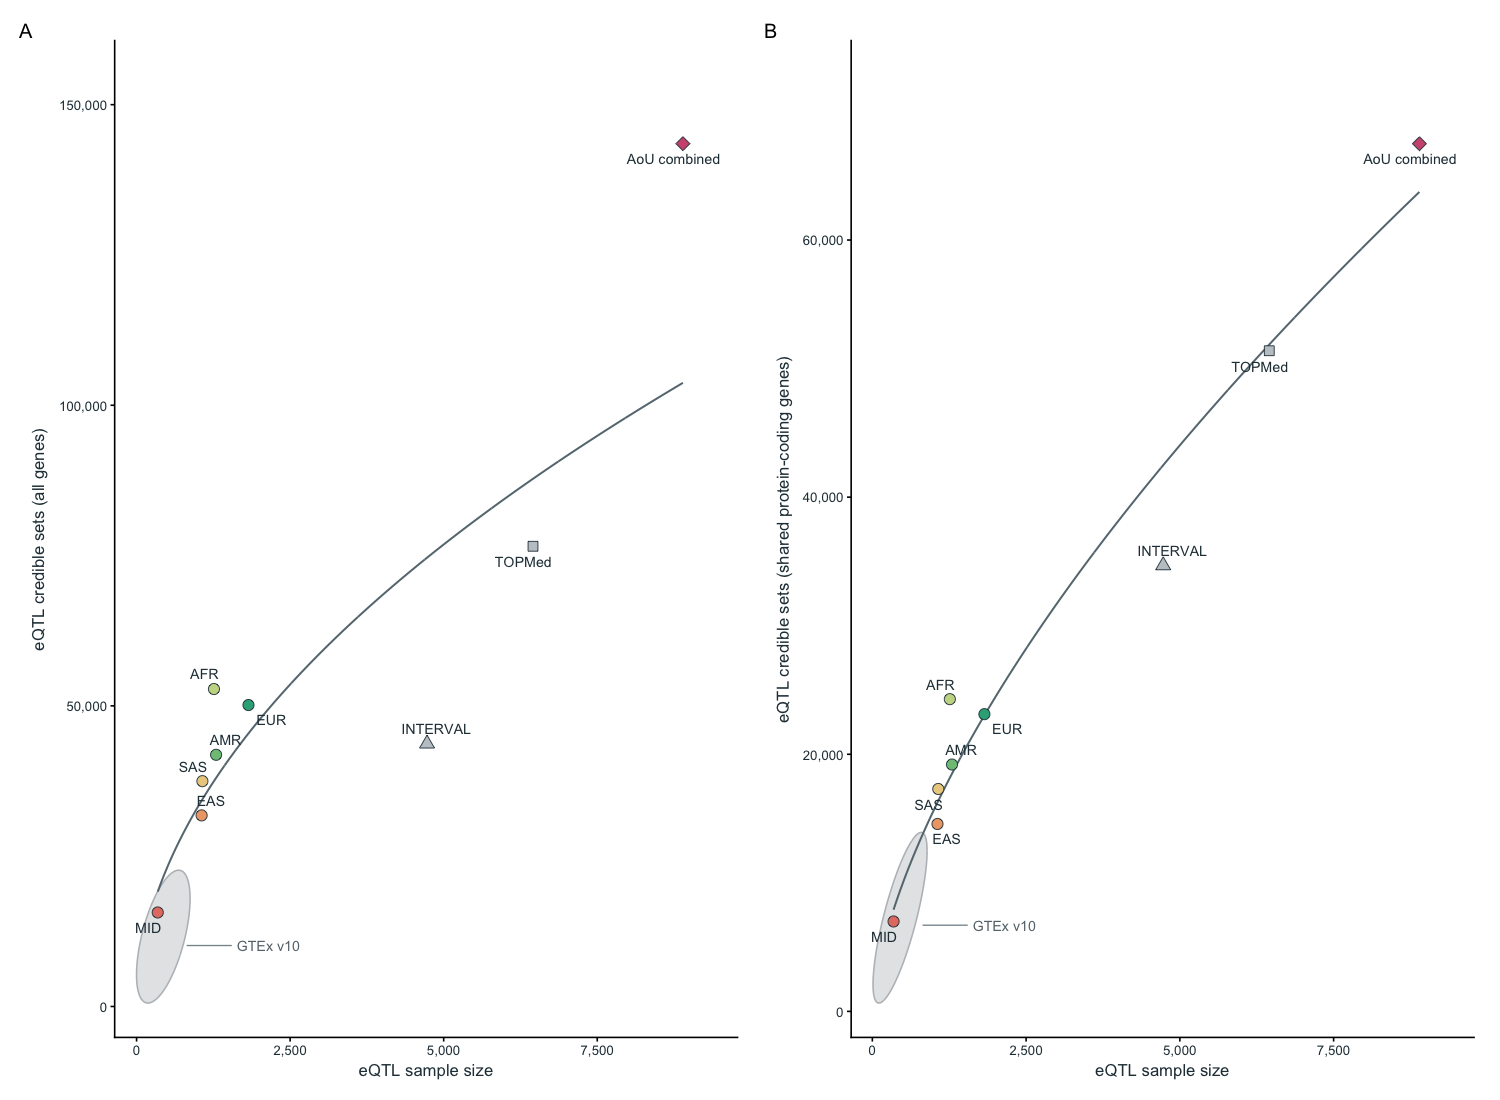

In [8]:
discovery_plot <- function(panel, y_label) {
  ggplot(panel$data, aes(sample_size, credible_sets)) +
    geom_polygon(data = panel$envelope$boundary, aes(sample_size, credible_sets),
      inherit.aes = FALSE, fill = "#E4E6E8", colour = "#B9BEC2", linewidth = 0.35) +
    geom_line(data = panel$curve, colour = "#667780", linewidth = 0.45) +
    geom_point(aes(fill = colour, shape = marker), size = 2.3, colour = "#263B45", stroke = 0.3) +
    ggrepel::geom_text_repel(aes(label = label), size = 2.4, colour = "#263B45",
      segment.colour = "#87949A", segment.size = 0.25, seed = 14, max.overlaps = Inf) +
    annotate("segment", x = max(panel$gtex$sample_size), xend = max(panel$gtex$sample_size) * 1.9,
      y = median(panel$gtex$credible_sets), yend = median(panel$gtex$credible_sets),
      colour = "#87949A", linewidth = 0.3) +
    annotate("text", x = max(panel$gtex$sample_size) * 2.0, y = median(panel$gtex$credible_sets),
      label = "GTEx v10", size = 2.4, hjust = 0, colour = "#66737A") +
    scale_shape_identity() + scale_fill_identity() +
    scale_x_continuous(labels = scales::label_comma(), expand = expansion(mult = c(.04, .10))) +
    scale_y_continuous(labels = scales::label_comma(), expand = expansion(mult = c(.04, .12))) +
    labs(x = "eQTL sample size", y = y_label) +
    theme_classic(base_size = 8) +
    theme(legend.position = "none", axis.text = element_text(colour = "#263B45"),
      axis.title = element_text(colour = "#263B45"), plot.margin = margin(5, 8, 5, 5))
}

figure <- discovery_plot(discovery_panels$A, "eQTL credible sets (all genes)") +
  discovery_plot(discovery_panels$B, "eQTL credible sets (shared protein-coding genes)") +
  plot_layout(nrow = 1) + plot_annotation(tag_levels = "A")
print(figure)


## Save aggregate outputs

Save the display, study totals, fitted curves and GTEx tissue totals. No participant identifiers are exported.


In [9]:
save_plot(figure, "supplements/S14", 184, 85)
readr::write_tsv(imap_dfr(discovery_panels, ~mutate(.x$data, panel = .y)),
  output_file("supplements/S14_study_summaries.tsv"))
readr::write_tsv(imap_dfr(discovery_panels, ~mutate(.x$curve, panel = .y)),
  output_file("supplements/S14_regression_curves.tsv"))
readr::write_tsv(gtex_counts, output_file("supplements/S14_gtex_tissue_summaries.tsv"))


Export aggregate plot: supplements/S14
